# Experimento para utilizar o dataset do Twitter15

**Questão principal:** A estrutura das cascatas de rumores falsos difere da de verdadeiros? E a remoção de quais contas reduz mais o alcance?

**Teste de Hipótese:** \
H1: cascatas falsas são maiores, mais profundas e mais rápidas que as verdadeiras. \
H2: remover as contas centrais reduz mais o alcance do que remover contas aleatórias.

##### Imports

In [7]:
import sys
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# o notebook roda de dentro da pasta notebooks, então sobe um nível até a raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import experimento_twitter15 as cc

##### Configurações

In [8]:
PASTA_DATASET = RAIZ / "dados" / "brutos" / "twitter15"
CLASSES = ("false", "true")   # só boatos falsos e verdadeiros
KS = (1, 3, 5)                # quantidades de contas removidas na simulação

PASTA_FIGURAS = RAIZ / "resultados" / "twitter15_experimento" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# mesmas cores usadas nas figuras do fluxo principal
CORES = {"false": "#d1495b", "true": "#2e86ab"}

##### 1. Construção das cascatas

Cada cascata vira uma árvore: os nós são as contas e uma aresta de A para B significa que
B compartilhou a notícia a partir de A. A raiz é a conta que publicou primeiro.

In [9]:
cascatas = cc.carregar_cascatas(PASTA_DATASET, CLASSES)
print(len(cascatas), 'cascatas carregadas')
pd.Series([T.graph['rotulo'] for T in cascatas.values()]).value_counts()

742 cascatas carregadas


true     372
false    370
Name: count, dtype: int64

##### 2. Métricas de cada cascata

| Métrica | Pergunta central |
|---|---|
| `tamanho` | Quantas contas a notícia alcançou? |
| `profundidade` | Qual é a corrente de propagação mais longa? |
| `ramificacao` | Em média, quantas pessoas compartilham a partir de cada conta que propagou? |
| `velocidade_min` | Em quantos minutos a cascata alcança metade das suas contas? (menor = mais rápida) |

In [10]:
metricas = cc.tabela_metricas(cascatas)
metricas.head()

,id_cascata,rotulo,tamanho,profundidade,ramificacao,velocidade_min
0,265953285247209472,false,209,2,34.666667,28.220
1,273182568298450945,false,354,2,35.300000,23.300
2,273278761909239808,false,386,2,64.166667,23.750
3,295152287901417472,true,103,2,25.500000,72.015
4,295944137948151809,false,1984,5,6.082822,4529.980


**Valor típico (mediana) de cada métrica, por classe:**

In [11]:
COLUNAS = ['tamanho', 'profundidade', 'ramificacao', 'velocidade_min']
medianas = metricas.groupby('rotulo')[COLUNAS].median().round(1)
medianas

,tamanho,profundidade,ramificacao,velocidade_min
rotulo,,,,
false,205.0,3.0,10.5,48.5
true,195.0,3.0,12.3,29.7


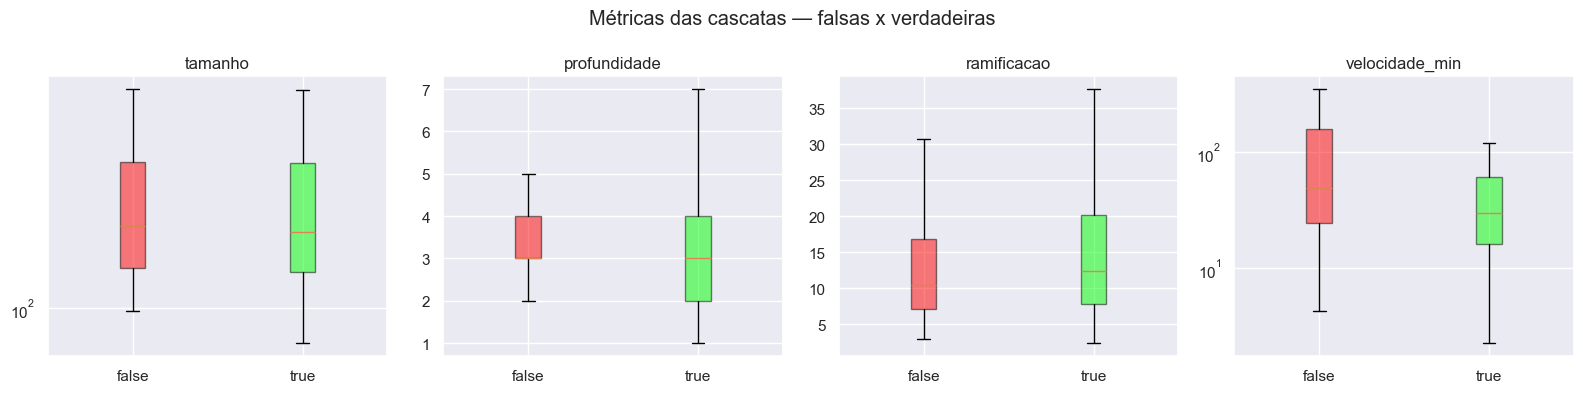

In [12]:
sns.set_theme('notebook', 'darkgrid')
fig, eixos = plt.subplots(1, 4, figsize=(16, 4))
for ax, coluna in zip(eixos, COLUNAS):
    dados = [metricas.loc[metricas.rotulo == c, coluna] for c in CLASSES]
    caixas = ax.boxplot(dados, tick_labels=CLASSES, showfliers=False, patch_artist=True)
    for caixa, c in zip(caixas['boxes'], CLASSES):
        caixa.set_facecolor(CORES[c])
        caixa.set_alpha(0.5)
    ax.set_title(coluna)

eixos[0].set_yscale('log')
eixos[3].set_yscale('log')
fig.suptitle('Métricas das cascatas: falsas e verdadeiras')
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / 'metricas.png', dpi=150)
plt.show()

##### 3. Remoção de contas centrais

**Conta Central**: a conta que tem maior galho (maior alcance).

A análise de conta central é a métrica mais importante do nosso trabalho, visto que ela demonstra não só o impacto que uma conta tem na propagação das informações para outras contas, mas também nos permite definir com estatística como evitar essa propagação para aquelas notícias que forem falsas.

Pensando nisso, para cada cascata removemos k contas de dois jeitos e medimos quanto % do alcance se perde:

- centrais: as k contas de maior impacto;
- aleatórias: k contas aleatórias.

O que queremos observar aqui é se ao remover as contas centrais o alcance é significativamente diferente das contas aleatórias, o que apontaria para uma difusão mais propagada por contas específicas.

In [13]:
remocao = cc.simular_remocao(cascatas, ks=KS)
tabela_remocao = (remocao.groupby(['rotulo', 'estrategia', 'k'])['perda_pct'].median().unstack('k').round(1))
tabela_remocao   # mediana do % de alcance perdido

k                    1    3     5
rotulo estrategia                
false  aleatorias  0.6  1.7   3.1
       centrais    3.6  8.1  11.0
true   aleatorias  0.6  1.9   3.1
       centrais    3.6  7.7  10.4

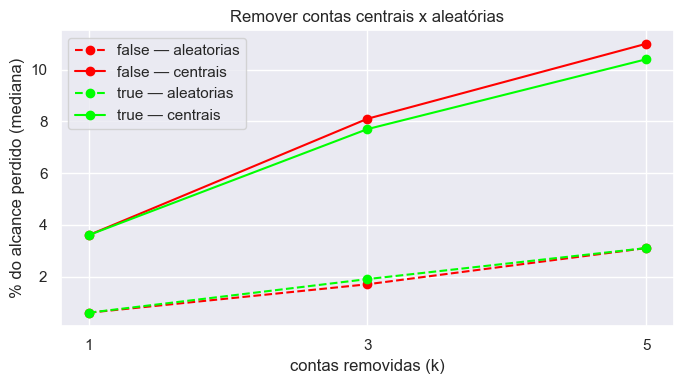

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
for (rotulo, estrategia), linha in tabela_remocao.iterrows():
    ax.plot(
        linha.index,
        linha.values,
        marker='o',
        color=CORES[rotulo],
        linestyle='-' if estrategia == 'centrais' else '--',
        label=f'{rotulo}, {estrategia}'
    )
ax.set_xticks(KS)
ax.set_xlabel('contas removidas (k)')
ax.set_ylabel('% do alcance perdido (mediana)')
ax.set_title('Remover contas centrais x aleatórias')
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / 'remocao.png', dpi=150)
plt.show()

##### 4. Conclusão da análise métrica

**Estrutura das cascatas (H1 - falha em rejeitar a hipótese nula).**

Há evidências estatísticas que apontam na similaridade estrutural entre os dois tipos de notícia:

- **Tamanho:** praticamente igual (205 x 195 contas).
- **Profundidade:** igual (3 saltos), as cascatas são bem rasas.
- **Ramificação:** um pouco maior nas verdadeiras (12,3 x 10,5 pessoas por conta que repostam).
- **Velocidade:** é a diferença mais clara, mas, inesperadamente, a favor das verdadeiras.

Ou seja, neste dataset as notícias falsas não são maiores, mais profundas nem mais rápidas.

**Remoção de contas centrais (H2 - hipótese nula rejeitada).**

Remover as contas centrais corta muito mais alcance do que remover contas ao acaso:

| k | Centrais | Aleatórias |
|---|---|---|
| 1 | 3,6% | 0,6% |
| 3 | ~8% | ~1,8% |
| 5 | ~11% | 3,1% |

Focar nas contas centrais é mais eficaz que agir com aleatoriedade, e isso vale tanto para notícias falsas quanto para verdadeiras. Mesmo assim o efeito é limitado, porque o alcance, quando removemos 5 contas, se mantém em cerca de 89%. É válido ressaltar que isso se deve a estrutura atípica que os grafos demonstraram, onde a maior parte das informações são propagadas diretamente pelo autor (um único nó).

Ou seja, a estrutura sozinha não diferencia notícias falsas de verdadeiras. Mas consegue mostrar que métricas como velocidade de propagação e remoção de contas podem ser eficientes na distinção dos dois tipos.